# V30: fixed 40/60 prior passes the CPU gross guard

One normalized40%Gemma/60%alignedLlama candidate, no reverse pass, no fitting.
Uniform gain versus H60 passes the fixed−0.005guard. Actual GPU qualification
and an official submission have not run. Original-training-overlapping, previously inspected
cohorts: descriptive results only, not independent CV or a hidden-score forecast.
[Protocol](../docs/SPAN_030_PLAN.md) · [CPU result](../docs/SPAN_030_CPU_RESULTS.md).

,cohort,rows,prompt_groups,H60_loss,base50_loss,candidate40_loss,gain_vs_H60,removal_gain,weight_gain,group95_low,group95_high
0,control,256,256,0.598234,0.599429,0.590901,0.007334,-0.001194,0.008528,0.004056,0.010338
1,uniform,512,512,0.652988,0.654242,0.645378,0.007610,-0.001254,0.008864,0.005311,0.009990
2,long,64,64,0.896484,0.896528,0.896378,0.000106,-0.000043,0.000150,-0.004949,0.005132


,cohort,class,gain_vs_H60
0,control,winner_model_a,0.007939
1,control,winner_model_b,0.006325
2,control,winner_tie,0.007788
3,uniform,winner_model_a,0.007754
4,uniform,winner_model_b,0.009067
5,uniform,winner_tie,0.006279
6,long,winner_model_a,0.001268
7,long,winner_model_b,0.006257
8,long,winner_tie,-0.010441


Decision: prepare_actual_two_role_qualification ; fixed gross threshold: -0.005
CPU elapsed: 1.7475047810003161 seconds / 300
Only one quality variant. Original training overlap; no independent CV or hidden forecast.


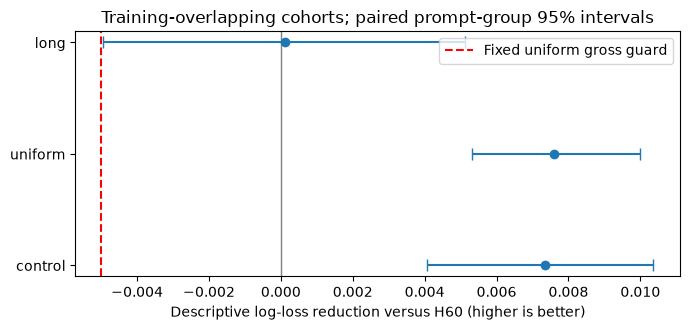

Sequentially selected after failed60/40prior; cumulative trials: [[0.6, 0.4], [0.4, 0.6]]
H76CPUguard passes; actualGPUqualification/official remain unperformed. No hidden-score forecast.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_030';r=json.loads((PUB/'quality_replay.json').read_text())
rows=[];classes=[]
for name,c in r['cohorts'].items():
 v,w,d=c['versus_incumbent'],c['weight_ablation'],c['removal'];lo,hi=v['paired_group95']
 rows.append({'cohort':name,'rows':c['rows'],'prompt_groups':c['prompt_groups'],
  'H60_loss':v['baseline']['log_loss'],'base50_loss':w['baseline']['log_loss'],
  'candidate40_loss':v['candidate']['log_loss'],'gain_vs_H60':v['loss_reduction'],
  'removal_gain':d['loss_reduction'],'weight_gain':w['loss_reduction'],'group95_low':lo,'group95_high':hi})
 for label,gain in v['class_loss_reduction'].items():classes.append({'cohort':name,'class':label,'gain_vs_H60':gain})
table=pd.DataFrame(rows);display(table);display(pd.DataFrame(classes))
print('Decision:',r['decision'],'; fixed gross threshold:',r['fixed_gross_regression_threshold'])
print('CPU elapsed:',r['elapsed_cpu_seconds'],'seconds /',r['cpu_cap_seconds'])
print('Only one quality variant. Original training overlap; no independent CV or hidden forecast.')
fig,ax=plt.subplots(figsize=(7,3.4));x=table.gain_vs_H60.to_numpy()
ax.errorbar(x,table.cohort,xerr=[x-table.group95_low.to_numpy(),table.group95_high.to_numpy()-x],fmt='o',capsize=4)
ax.axvline(0,color='grey',linewidth=1);ax.axvline(-.005,color='red',linestyle='--',label='Fixed uniform gross guard')
ax.set_xlabel('Descriptive log-loss reduction versus H60 (higher is better)')
ax.set_title('Training-overlapping cohorts; paired prompt-group 95% intervals');ax.legend();fig.tight_layout()
ROOT=Path.home()/'database/llm_classification_finetuning/runs/span_030';(ROOT/'figures').mkdir(exist_ok=True)
fig.savefig(ROOT/'figures/fixed_prior_gains.png',dpi=160,bbox_inches='tight');plt.show()
for name in ['resource_close.json','final_leaderboard.json']:
 p=PUB/name
 if p.exists():print(name,json.loads(p.read_text()))
print('Sequentially selected after failed60/40prior; cumulative trials:',r['cumulative_twoexpert_priors_tested'])
print('H76CPUguard passes; actualGPUqualification/official remain unperformed. No hidden-score forecast.')